# Aula 9 - Testes Não Paramétricos

## Motivação

Um hospital compara o tempo de internação de pacientes que receberam
dois tratamentos, A e B. No grupo B, todos receberam alta entre 4 e 9
dias. No grupo A, sete pacientes saíram em até 5 dias, mas um teve uma
complicação grave e ficou **120 dias** internado. Um único paciente pode
mudar a conclusão sobre qual tratamento é melhor?

Pense na pergunta antes de fazer qualquer conta. Se você fosse paciente
desse hospital, qual tratamento escolheria? Olhando para a maioria dos
pacientes, A parece melhor: quase todos saíram mais cedo. Olhando para o
total de dias de leito, A parece pior, por causa de um único caso grave.
As duas impressões são legítimas, e é justamente essa tensão que esta
aula vai organizar.

Na Aula 8, os testes paramétricos compararam **médias** e supuseram que
os dados seguiam distribuições conhecidas, como a normal. Com oito
pacientes por grupo e um valor tão extremo, essas suposições ficam
frágeis: a média de A passa a descrever mais o paciente de 120 dias do
que os outros sete. Nesta aula, aprendemos uma estratégia diferente. Em
vez de usar os valores, usamos a **posição** de cada valor na ordenação,
chamada de **posto**. Com os postos, o paciente de 120 dias continua na
análise, mas deixa de dominá-la.

O roteiro tem três partes. Primeiro, resolvemos o exemplo do hospital
passo a passo com o teste de Mann-Whitney, do primeiro posto até o
*p*-valor. Depois, aplicamos a mesma ideia a um teste A/B de layout de
site. Por fim, usamos os postos para entender a diferença entre as
correlações de Pearson e de Spearman.

> **O que muda quando comparamos posições em vez de valores?**

## Objetivos de aprendizagem

Ao final deste roteiro, você será capaz de:

1.  Construir postos a partir de dois grupos, inclusive com empates.
2.  Calcular as somas de postos $W$ e a estatística $U$ do teste de
    Mann-Whitney.
3.  Obter o *p*-valor do Mann-Whitney pela aproximação normal.
4.  Distinguir a pergunta sobre médias (Welch) da pergunta sobre
    ordenação (Mann-Whitney).
5.  Comparar as correlações de Pearson e de Spearman e explicar quando
    cada uma é adequada.

> **Como usar este roteiro**
>
> Os dados do hospital e do teste de layout são pequenos e são digitados
> no próprio roteiro. O caso 2 reutiliza a base `mtcars`, salva em
> `mtcars/data/`. Não é necessário instalar novas bibliotecas.

# 1. Preparando o ambiente

Começamos pelas bibliotecas e pela função `report`, já usada na Aula 8,
que resume o resultado de um teste em uma linha. Os dados de cada
exemplo são apresentados na seção em que são usados.

In [1]:
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy import stats

sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Resume o resultado de um teste em uma linha legível
def report(name, result, stat="estatística"):
    parts = [f"{stat} = {result.statistic:.3f}"]
    if hasattr(result, "df"):
        parts.append(f"gl = {result.df:.4g}")
    p = result.pvalue
    parts.append("p < 0.001" if p < 0.001 else f"p = {p:.3f}")
    print(f"{name}: " + " · ".join(parts))

# 2. Recapitulação: o que precisamos lembrar

## 2.1 As peças do teste

O teste de Mann-Whitney parece novo, mas é construído com peças que você
já conhece. Vale relembrá-las antes do cálculo, porque cada uma vai
reaparecer em algum passo da seção 3.

**Hipóteses e *p*-valor.** Todo teste confronta uma hipótese nula $H_0$,
que diz que não há efeito, com uma alternativa $H_1$, que diz que há. O
*p*-valor responde a uma pergunta condicional: **se $H_0$ fosse
verdadeira**, qual seria a probabilidade de obter um resultado tão ou
mais extremo que o observado? Um *p*-valor pequeno significa que o
resultado seria raro em um mundo sem efeito. Neste roteiro, todos os
testes são bilaterais: uma diferença em qualquer sentido conta como
evidência contra $H_0$ (Aula 7).

**Duas formas de obter o *p*-valor.** Na Aula 7, obtivemos o *p*-valor
de um teste de permutação simulando muitos cenários sem efeito. O
Mann-Whitney também poderia ser resolvido assim, e com amostras pequenas
daria o chamado *p*-valor exato. Nesta aula, porém, **não** seguiremos
esse caminho. Usaremos a **aproximação pela curva normal**, que exige
apenas duas fórmulas e funciona para amostras de qualquer tamanho.

**Estatística de teste como sinal ÷ ruído.** Na Aula 8, todo teste
dividiu um efeito observado, o sinal, pela variação que o acaso
produziria, o ruído. O resultado mede quantas “unidades de acaso” o
efeito ocupa. Quando essa razão segue a curva normal padrão, o *p*-valor
é simplesmente a área nas duas caudas da curva, além do valor observado.
É assim que obteremos o *p*-valor do Mann-Whitney na seção 3.9. Como
essa curva é central para a aula, a seção 2.2 faz uma revisão mais
detalhada dela.

**Média e mediana diante de extremos.** Na Aula 5, vimos que a média é
puxada por valores extremos, enquanto a mediana depende só de quem está
no meio da ordenação. Um bilionário que entra em uma sala muda a renda
média, mas quase não muda a mediana. Os postos levam essa mesma robustez
da estatística descritiva para um teste de hipóteses.

## 2.2 Revisão estendida: a distribuição Z

A distribuição normal padrão, também chamada de distribuição **Z**, já
apareceu várias vezes no curso: no z-score do `StandardScaler` da Aula
6, na regra dos “2 erros-padrão” da Aula 7 e no teste *Z* de proporções
da Aula 8. Nesta aula, ela é a peça que transforma a estatística $U$ em
um *p*-valor. Vale, então, olhar para ela com calma.

**Padronizar: a quantos desvios-padrão da média?** Imagine que a altura
dos adultos de uma cidade tenha média de 170 cm e desvio-padrão de 10
cm. Uma pessoa com 190 cm é alta, mas quão alta? A pergunta fica mais
fácil de responder se medirmos a distância em desvios-padrão:

$$
z = \frac{x - \mu}{\sigma}
$$

Para 190 cm, $z = (190 - 170)/10 = +2$: a pessoa está dois
desvios-padrão acima da média. Para 155 cm,
$z = (155 - 170)/10 = -1{,}5$: um desvio-padrão e meio abaixo. O sinal
indica o lado, e o tamanho indica a distância. Foi exatamente essa conta
que o `StandardScaler` da Aula 6 fez com cada coluna.

**Uma curva para todas as normais.** Distribuições normais podem ter
qualquer média e qualquer desvio-padrão: alturas em centímetros, tempos
em segundos, notas de prova. Mas, depois de padronizadas, todas viram
**a mesma curva**, com média 0 e desvio-padrão 1. Essa é a distribuição
normal padrão. A vantagem é enorme: em vez de uma tabela para cada
normal, basta conhecer uma única curva.

**A regra 68-95-99,7.** Na normal padrão, a área sob a curva entre dois
valores é a probabilidade de observar um valor nesse intervalo. Três
faixas valem a pena memorizar:

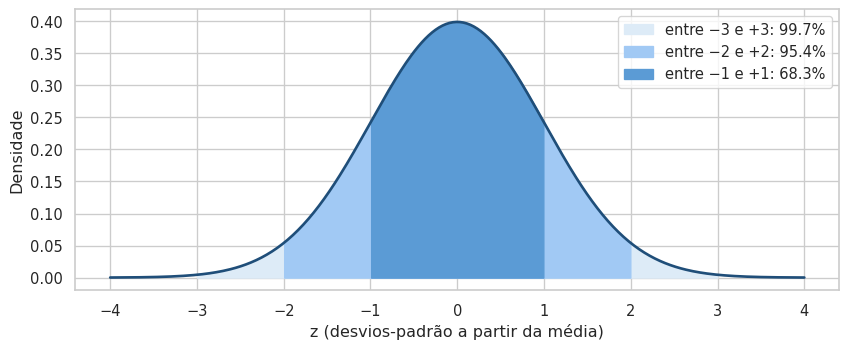

In [3]:
# Normal padrão com as faixas de 1, 2 e 3 desvios-padrão
grid = np.linspace(-4, 4, 400)
density = stats.norm.pdf(grid)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(grid, density, color="#1F4E79", linewidth=2)
for k, color in [(3, "#DDEBF7"), (2, "#A1C9F4"), (1, "#5B9BD5")]:
    area = stats.norm.cdf(k) - stats.norm.cdf(-k)
    ax.fill_between(grid, density, where=np.abs(grid) <= k, color=color,
                    label=f"entre −{k} e +{k}: {area:.1%}")
ax.set(xlabel="z (desvios-padrão a partir da média)", ylabel="Densidade",
       xticks=range(-4, 5))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

Cerca de 68% dos valores ficam a menos de 1 desvio-padrão da média, 95%
a menos de 2, e 99,7% a menos de 3. Daí vem a regra prática da Aula 7:
sob o acaso, uma estatística padronizada quase nunca passa de 2. Valores
além de 3 são raríssimos.

**Área é probabilidade.** O SciPy oferece três funções para trabalhar
com essas áreas:

In [4]:
# Áreas da normal padrão e o caminho inverso, da área para o z
print(f"P(Z ≤ −2) = {stats.norm.cdf(-2):.4f}")
print(f"P(Z ≥ +2) = {stats.norm.sf(2):.4f}")
print(f"z que deixa 2,5% em cada cauda = {stats.norm.ppf(0.975):.2f}")

P(Z ≤ −2) = 0.0228
P(Z ≥ +2) = 0.0228
z que deixa 2,5% em cada cauda = 1.96

A curva é simétrica, por isso a área abaixo de −2 é igual à área acima
de +2, cerca de 2,3% cada. O valor 1,96 é o famoso limite dos 95%: entre
−1,96 e +1,96 ficam 95% da área, e sobram 2,5% em cada cauda.

**Do Z ao *p*-valor bilateral.** Em um teste bilateral, um resultado tão
extremo **para qualquer lado** conta como evidência contra $H_0$. Por
isso, o *p*-valor soma as duas caudas além de $|z|$:

$$
p = 2 \times P(Z \leq -|z|)
$$

| $|z|$ observado | *p*-valor bilateral | Leitura com $\alpha = 0{,}05$ |
|------------------------|------------------------|------------------------|
| 1,00 | 0,317 | Comum sob $H_0$ |
| 1,96 | 0,050 | Exatamente no limite |
| **2,22** | **0,026** | **Raro: rejeita $H_0$. É o valor que encontraremos na seção 3.9** |
| 2,58 | 0,010 | Muito raro |
| 3,00 | 0,003 | Raríssimo |

Quanto mais longe de zero está o $z$, menor a área nas caudas e menor o
*p*-valor. Não é preciso decorar a tabela: basta lembrar que $|z|$ acima
de cerca de 2 corresponde a *p* abaixo de 0,05.

**Por que a estatística $U$ fica perto de uma normal?** $U$ é uma soma
de muitas parcelas pequenas: cada um dos 64 duelos vale 0, ½ ou 1. Pelo
teorema central do limite, somas de muitas parcelas tendem a ter
distribuição em forma de sino, mesmo quando cada parcela isolada não
tem. É isso que autoriza usar a curva normal para obter o *p*-valor do
Mann-Whitney. Com grupos muito pequenos, de poucas observações, a
aproximação piora, e o *p*-valor exato passa a ser preferível.

# 3. Tratamentos A e B, passo a passo

## 3.1 Os dados

O hospital acompanhou oito pacientes em cada tratamento e registrou
quantos dias cada um ficou internado. Como os dados são poucos, eles são
digitados diretamente no roteiro:

In [5]:
# Tempos de internação dos dois tratamentos, em dias
days_a = [1, 2, 2, 3, 3, 4, 5, 120]
days_b = [4, 5, 5, 6, 6, 7, 8, 9]

uti = pd.DataFrame(
    {
        "tratamento": ["A"] * len(days_a) + ["B"] * len(days_b),
        "dias": days_a + days_b,
    }
)

Antes de qualquer medida, vale **olhar** para os dados. No gráfico
abaixo, cada ponto é um paciente. O painel de cima mostra a escala
completa, de 0 a 120 dias. O de baixo amplia a faixa de 0 a 10 dias,
onde estão quase todos os pacientes:

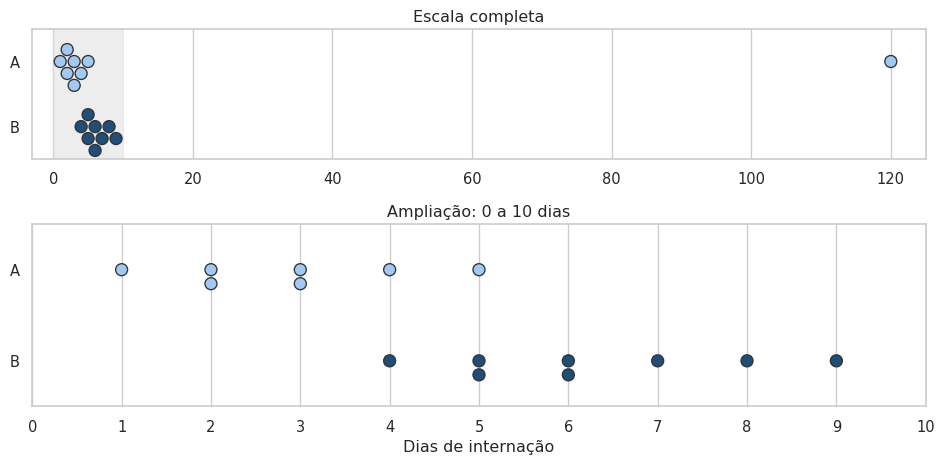

In [6]:
# Cada paciente em um ponto: escala completa e ampliação de 0 a 10 dias
fig, axes = plt.subplots(2, 1, figsize=(10, 5), height_ratios=[1, 1.4])

for ax, xlim in zip(axes, [(-3, 125), (0, 10)]):
    sns.swarmplot(
        data=uti, x="dias", y="tratamento", hue="tratamento",
        palette={"A": "#A1C9F4", "B": "#1F4E79"}, size=9,
        edgecolor="#333333", linewidth=1, legend=False, ax=ax,
    )
    ax.set(xlim=xlim, ylabel="")

axes[0].axvspan(0, 10, color="#DDDDDD", alpha=.5)
axes[0].set(title="Escala completa", xlabel="")
axes[1].set(title="Ampliação: 0 a 10 dias", xlabel="Dias de internação",
            xticks=range(11))
plt.tight_layout()
plt.show()

Na escala completa, quase todos os pontos se amontoam no início do eixo,
e um único paciente de A fica isolado em 120 dias. Na ampliação, aparece
o que a escala completa escondia: os sete pacientes restantes de A ficam
entre 1 e 5 dias, à esquerda de praticamente todos os pacientes de B,
que ficam entre 4 e 9 dias.

## 3.2 As distribuições de cada grupo

O gráfico de pontos mostra cada paciente. Para enxergar a **forma** de
cada distribuição, usamos histogramas, um para cada tratamento. Há um
obstáculo: com o paciente de 120 dias no mesmo eixo, todas as outras
barras ficariam espremidas no início do gráfico. Por isso, o eixo
horizontal é **interrompido**. O trecho da esquerda mostra de 0 a 10
dias, e o da direita, de 115 a 125 dias. Cada barra tem a largura de um
dia, e as linhas marcam a média e a mediana:

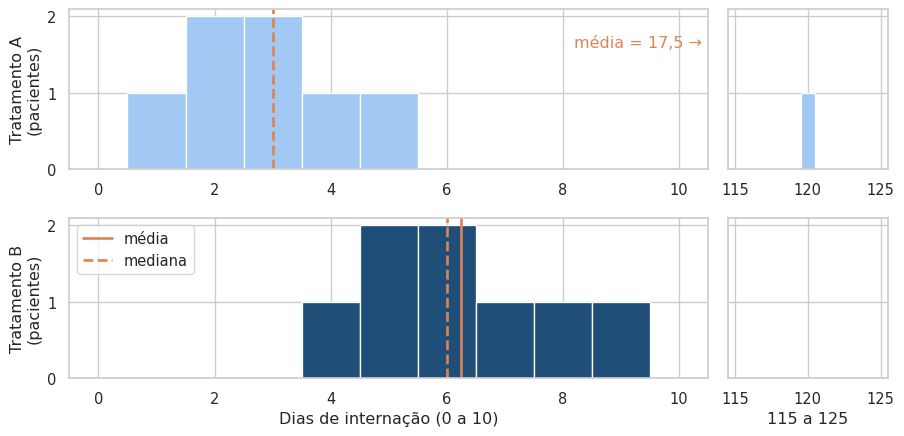

In [7]:
# Histogramas com o eixo interrompido entre 10 e 115 dias
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharey=True,
                         gridspec_kw={"width_ratios": [4, 1]})

for row, (group, color) in zip(axes, [("A", "#A1C9F4"), ("B", "#1F4E79")]):
    values = uti.loc[uti["tratamento"] == group, "dias"]
    for ax, (low, high) in zip(row, [(0, 10), (115, 125)]):
        ax.hist(values, bins=np.arange(low - .5, high + 1), color=color,
                edgecolor="white")
        ax.set_xlim(low - .5, high + .5)
        for stat, style, label in [(values.mean(), "-", "média"),
                                   (values.median(), "--", "mediana")]:
            if low <= stat <= high:
                ax.axvline(stat, color="#DD8452", linestyle=style, linewidth=2,
                           label=label)
    row[0].set(ylabel=f"Tratamento {group}\n(pacientes)", yticks=[0, 1, 2])

axes[0, 0].annotate("média = 17,5 →", xy=(10.4, 1.6), ha="right",
                   color="#DD8452")
axes[1, 0].legend(loc="upper left")
axes[1, 0].set_xlabel("Dias de internação (0 a 10)")
axes[1, 1].set_xlabel("115 a 125")
fig.subplots_adjust(wspace=.05, hspace=.3)
plt.show()

Agora as duas formas ficam evidentes:

-   **Tratamento B.** Os oito pacientes formam um bloco compacto entre 4
    e 9 dias, com o pico em 5 e 6 dias e os valores distribuídos de modo
    aproximadamente simétrico. Média e mediana praticamente coincidem:
    quando os dados são simétricos e sem extremos, as duas medidas
    contam a mesma história.
-   **Tratamento A.** Sete pacientes se concentram entre 1 e 5 dias, e
    um único paciente aparece isolado no trecho da direita, em 120 dias.
    É uma **assimetria à direita** acentuada: a maior parte dos valores
    é pequena, e uma cauda longa se estende até um valor extremo. A
    mediana, em 3 dias, continua junto da maioria dos pacientes. A
    média, em 17,5 dias, cai no trecho interrompido do eixo, uma região
    onde **não há nenhum paciente**.

Esse é o primeiro sinal de alerta: quando a média cai em uma região
vazia dos dados, ela deixa de representar um paciente típico.

## 3.3 Assimetria e medidas-resumo

O histograma mostrou a forma de cada grupo. Agora, descrevemos essa
forma com números. O coeficiente de assimetria da Aula 5 transforma em
número o que o histograma mostrou:

In [8]:
# Coeficiente de assimetria de cada grupo
for group in ["A", "B"]:
    values = uti.loc[uti["tratamento"] == group, "dias"]
    print(f"Tratamento {group}: assimetria = {stats.skew(values):.2f}")

Tratamento A: assimetria = 2.26
Tratamento B: assimetria = 0.37

Como ler esses números? O coeficiente de assimetria diz para que lado a
distribuição se “inclina”, ou seja, para que lado ela se alonga, e com
que intensidade:

-   **O sinal indica a direção da cauda.** Um valor positivo indica uma
    cauda que se estende para a **direita**, na direção dos valores
    altos. A maior parte dos dados fica concentrada à esquerda, e alguns
    valores grandes puxam a distribuição para a direita. Um valor
    negativo indica o contrário, uma cauda à esquerda. Um valor próximo
    de zero indica uma distribuição equilibrada, com os dois lados
    parecidos.
-   **O tamanho indica a intensidade.** Como referência prática, valores
    entre −0,5 e 0,5 costumam ser lidos como distribuição
    aproximadamente simétrica, valores entre 0,5 e 1 (em módulo) como
    assimetria moderada, e valores acima de 1 como assimetria forte.

Com essa régua, os dois grupos ficam em lados opostos:

| Grupo | Assimetria | Leitura | O que se vê no histograma |
|------------------|------------------|------------------|------------------|
| B | 0,37 | Aproximadamente simétrica, com uma leve cauda à direita | Pico em 5 e 6 dias, com os valores de 7, 8 e 9 dias um pouco mais espalhados à direita do que os de 4 dias à esquerda |
| A | 2,26 | Assimetria forte à direita | Sete pacientes concentrados entre 1 e 5 dias e um único paciente isolado em 120 dias |

Por que a assimetria de A é tão grande? A fórmula da Aula 5 eleva ao
**cubo** a distância de cada valor até a média. O cubo tem duas
propriedades importantes: preserva o sinal, então valores abaixo da
média contribuem negativamente e valores acima, positivamente; e amplia
muito as distâncias grandes. Em A, os sete pacientes de 1 a 5 dias ficam
abaixo da média de 17,5 dias, a uma distância de 12 a 16 dias, e somam
juntos cerca de −22 mil. O paciente de 120 dias está a 102,5 dias da
média, e o cubo dessa distância passa de **1 milhão**. Sozinho, ele
determina o resultado. Sem ele, a assimetria dos outros sete pacientes
cairia para cerca de 0,27, um valor de distribuição praticamente
simétrica.

O sinal positivo também combina com a relação entre média e mediana
vista na Aula 5: em uma distribuição com cauda à direita, a média é
puxada pela cauda e fica **acima** da mediana. Em B, a diferença é
pequena (6,25 contra 6). Em A, ela é enorme (17,5 contra 3). É
exatamente o tipo de dado em que média e desvio-padrão deixam de
representar bem o grupo. As medidas-resumo confirmam:

In [9]:
# Média, desvio-padrão, mediana e total de dias por tratamento
uti_summary = (
    uti
    .groupby("tratamento")
    .dias
    .agg(["mean", "std", "median", "sum"])
    .round(2)
)

uti_summary

As medidas apontam em direções opostas, e vale ler a tabela com calma:

-   **Média.** A média de A (17,50 dias) é quase o triplo da de B
    (6,25). Se olhássemos só para ela, concluiríamos que A é muito pior.
-   **Total de dias.** Dos 140 dias de leito de A, 120 vêm de um único
    paciente. Os outros sete somam apenas 20 dias.
-   **Desvio-padrão.** O de A chega a 41,4 dias, contra 1,7 em B. Esse
    número enorme não descreve uma variação “espalhada” entre os
    pacientes: ele é praticamente todo produzido pelo valor extremo.
-   **Mediana.** A mediana de A (3 dias) é a **metade** da de B (6
    dias). Se olhássemos só para ela, concluiríamos que A é melhor.

A média e a mediana não estão erradas. Elas respondem a perguntas
diferentes: a média distribui o total de dias igualmente entre os
pacientes, e a mediana descreve o paciente do meio.

## 3.4 O que diz a comparação de médias

Aplicamos o teste de Welch da Aula 8:

In [10]:
# Teste t de Welch comparando os tempos médios
group_a = uti.loc[uti["tratamento"] == "A", "dias"]
group_b = uti.loc[uti["tratamento"] == "B", "dias"]

welch_uti = stats.ttest_ind(group_a, group_b, equal_var=False)

report("t de Welch", welch_uti, stat="t")

t de Welch: t = 0.767 · gl = 7.023 · p = 0.468

Com $p \approx 0{,}47$, não rejeitamos a igualdade das médias. Por que
uma diferença de 11,25 dias, quase o dobro da média de B, não é
suficiente? Lembre que o *t* divide o sinal pelo ruído. O sinal é a
diferença de médias, 11,25 dias. O ruído é o erro-padrão, que depende
dos desvios-padrão dos grupos. Como o desvio-padrão de A foi inflado
pelo paciente de 120 dias, o erro-padrão chega a cerca de 14,7 dias,
maior que a própria diferença. O resultado é $t \approx 0{,}77$: a
diferença observada ocupa menos de um erro-padrão.

Três cuidados ajudam a interpretar esse resultado:

-   **O teste não errou a conta.** 17,5 dias é a média correta dos oito
    pacientes, e o teste respondeu exatamente à pergunta feita: há
    evidência de que as médias diferem? Com estes dados, não há.
-   **Não rejeitar $H_0$ não prova que os tratamentos são
    equivalentes.** Significa apenas que a comparação de médias não
    encontrou evidência suficiente.
-   **Excluir o paciente não é uma opção.** A complicação foi um efeito
    adverso do tratamento A e faz parte do resultado. Tirá-lo esconderia
    justamente o que o tratamento causou.

Precisamos, então, de uma pergunta diferente: uma que mantenha o
paciente na análise, mas não deixe que a **distância** dele aos demais
domine o resultado.

## 3.5 Construindo os postos

Pense em uma corrida. O resultado oficial registra a **ordem de
chegada**: primeiro, segundo, terceiro. Se o último colocado chega uma
hora depois de todos, ele continua sendo o último, e não “vale mais” por
ter chegado muito atrasado. O **posto** aplica essa mesma ideia aos
dados: é a posição de cada observação na ordenação de todas elas, da
menor para a maior.

A construção tem três passos:

1.  **Juntar** os 16 pacientes, ignorando o grupo.
2.  **Ordenar** do menor para o maior tempo e numerar as posições de 1 a
    16.
3.  **Resolver os empates.** Valores iguais recebem a média das posições
    que ocupam. Os três pacientes com 5 dias, por exemplo, ocupam as
    posições 8, 9 e 10 e recebem, cada um, o posto $(8 + 9 + 10)/3 = 9$.

Fazemos cada passo separadamente e, no fim, reunimos tudo em uma única
tabela:

In [11]:
# Passo 1: juntar os 16 pacientes e ordenar do menor para o maior tempo
uti_sorted = uti.sort_values("dias", kind="stable").reset_index(drop=True)

# Passo 2: numerar as posições de 1 a 16
positions = np.arange(1, len(uti_sorted) + 1)

# Passo 3: calcular os postos, com a média das posições nos empates
ranks = uti_sorted["dias"].rank(method="average")

# Combina os dados ordenados, as posições e os postos em uma tabela
ranked = uti_sorted.assign(posicao=positions, posto=ranks)

ranked.T

Leia a tabela linha a linha. A linha `posicao` numera os pacientes de 1
a 16, mesmo os empatados. A linha `posto` corrige os empates com a média
das posições: 2,5 para os dois pacientes com 2 dias (posições 2 e 3),
4,5 para os de 3 dias, 6,5 para os de 4 dias, 9 para os três de 5 dias e
11,5 para os de 6 dias. Por que tirar a média, e não dar a todos a menor
posição? Porque assim a soma total dos postos continua sendo
$1 + 2 + \dots + 16 = 136$, com ou sem empates, e nenhum grupo é
favorecido.

Agora observe o último paciente. Com 120 dias, ele recebe o posto 16. Na
escala de dias, ele estava a 111 dias do vizinho mais próximo, o
paciente de 9 dias. Na escala de postos, está a **uma posição** dele. A
ordem é preservada, e a distância desaparece.

Isso não significa que o paciente foi ignorado: ele continua na análise
e ocupa o maior posto. O que deixa de ser usado é a **magnitude** da
diferença. A importância clínica da complicação também não desaparece.
Ela apenas deixa de dominar o teste.

> **Os postos são uma espécie de normalização?**
>
> Em parte. Na Aula 6, vimos que “normalização” tem dois sentidos, e os
> postos têm algo de cada um:
>
> -   **Como o escalonamento, eliminam a unidade.** Dias, horas ou
>     segundos viram sempre posições de 1 a $N$.
> -   **Como o log, reduzem a influência dos extremos**, só que de forma
>     muito mais radical. A distância entre vizinhos passa a ser sempre
>     1, e só a ordem permanece.
>
> O gráfico compara os 16 pacientes em três escalas: os dias originais,
> o log dos dias e os postos.
>
> ``` python
> # Os mesmos 16 pacientes em três escalas: dias, log dos dias e postos
> scales = {
>     "Dias": ranked["dias"],
>     "log(dias)": np.log(ranked["dias"]),
>     "Postos": ranked["posto"],
> }
>
> fig, axes = plt.subplots(3, 1, figsize=(10, 4.5))
> for ax, (label, values) in zip(axes, scales.items()):
>     sns.swarmplot(x=values, hue=ranked["tratamento"], size=8, ax=ax,
>                   palette={"A": "#A1C9F4", "B": "#1F4E79"},
>                   edgecolor="#333333", linewidth=1, legend=(label == "Dias"))
>     ax.set(title=label, xlabel="")
> sns.move_legend(axes[0], "upper left", bbox_to_anchor=(1.01, 1),
>                 title="Tratamento")
> plt.tight_layout()
> plt.show()
> ```
>
> Linha 14  
> `move_legend` leva a legenda para fora da área do gráfico, para que
> ela não cubra os pontos.
>
> 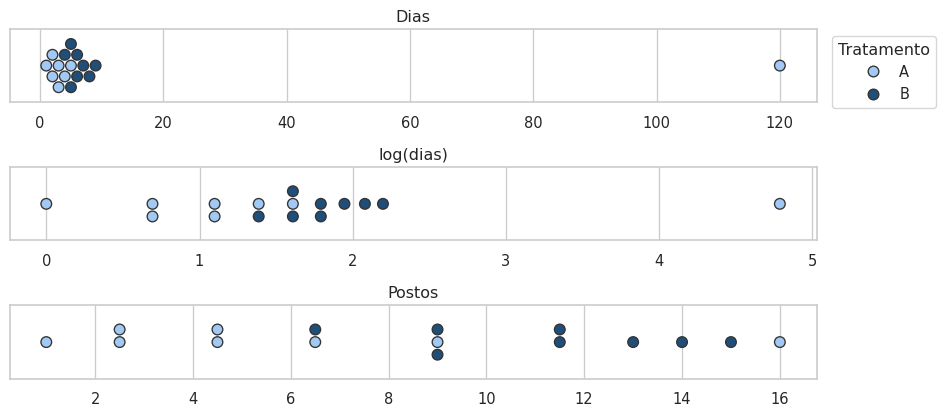
>
> Na escala de dias, o paciente de 120 dias fica isolado e espreme todos
> os outros no início do eixo. O log aproxima esse paciente dos demais,
> mas ele ainda se destaca à direita. Nos postos, os 16 pacientes ficam
> espaçados de forma regular, e o de 120 dias é apenas o último da fila.
>
> Três diferenças, porém, separam os postos de uma normalização
> propriamente dita:
>
> 1.  **O resultado não é uma normal.** Sem empates, os postos de 1 a
>     $N$ formam uma distribuição **uniforme**: cada posição aparece uma
>     única vez. No painel de baixo, a distribuição é praticamente
>     plana, e só os valores empatados aparecem empilhados. A forma de
>     sino usada na seção 3.9 não descreve os postos, e sim a
>     estatística $U$, que é uma soma de muitos duelos.
> 2.  **O posto depende das outras observações.** O log de 120 é sempre
>     o mesmo número. Já o posto do paciente de 120 dias é 16 nesta
>     amostra, mas mudaria se houvesse mais ou menos pacientes. Um posto
>     só tem significado dentro da amostra em que foi calculado.
> 3.  **A transformação não tem volta.** Do log é possível voltar aos
>     dias com a exponencial. Dos postos não: sabemos que o paciente
>     ficou mais tempo que todos, mas não quanto.
>
> Em resumo, os postos são uma transformação que **preserva a ordem e
> descarta as distâncias**. Existe uma técnica que vai um passo além e
> de fato aproxima os dados de uma normal: a **transformação inversa
> normal dos postos**, que troca cada posto pelo quantil correspondente
> da normal padrão. Ela é usada em áreas como a genética, mas foge do
> escopo desta aula.

## 3.6 Comparando os pares: a estatística $U$

Com os postos definidos, podemos comparar os grupos de uma forma muito
intuitiva: promovendo “duelos”. Cada paciente de A enfrenta cada
paciente de B, e em cada duelo perguntamos apenas quem ficou mais tempo
internado. Com 8 pacientes em cada grupo, são
$n_A \times n_B = 8 \times 8 = 64$ duelos.

Em cada duelo, só importa **quem** ficou mais tempo, e não por quantos
dias. O paciente de 120 dias vence todos os seus duelos, mas cada
vitória vale o mesmo que a de um paciente que ficou apenas um dia a
mais. Por isso, comparar os dias ou os postos dá exatamente o mesmo
resultado.

Na matriz, cada linha é um paciente de A, e cada coluna, um paciente de
B. O símbolo em cada célula indica o resultado do duelo do ponto de
vista de A:

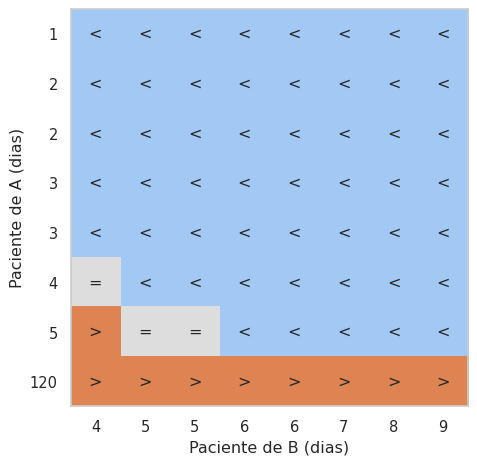

In [13]:
# Comparação de cada paciente de A com cada paciente de B
duels = np.sign(np.subtract.outer(days_a, days_b))

fig, ax = plt.subplots(figsize=(6, 5))
colors = ListedColormap(["#A1C9F4", "#DDDDDD", "#DD8452"])
ax.imshow(duels, cmap=colors, vmin=-1, vmax=1)
for (i, j), value in np.ndenumerate(duels):
    ax.text(j, i, {-1: "<", 0: "=", 1: ">"}[value], ha="center", va="center")
ax.set(xticks=range(8), xticklabels=days_b, yticks=range(8), yticklabels=days_a,
       xlabel="Paciente de B (dias)", ylabel="Paciente de A (dias)")
ax.grid(False)
plt.tight_layout()
plt.show()

A estatística $U$ conta esses pares. $U_A$ é o número de pares em que o
paciente de A fica **mais** tempo, e cada empate vale meio ponto. $U_B$
faz o mesmo para B:

In [14]:
# Contagem dos pares e estatísticas U de cada grupo
n_a, n_b = len(days_a), len(days_b)
a_less, ties_ab, a_more = (duels < 0).sum(), (duels == 0).sum(), (duels > 0).sum()

u_a = a_more + 0.5 * ties_ab
u_b = a_less + 0.5 * ties_ab

print(f"A < B: {a_less} · empates: {ties_ab} · A > B: {a_more}")
print(f"U_A = {u_a} · U_B = {u_b} · U_A + U_B = {u_a + u_b} = n_A × n_B")

A < B: 52 · empates: 3 · A > B: 9
U_A = 10.5 · U_B = 53.5 · U_A + U_B = 64.0 = n_A × n_B

Vamos ler a matriz com atenção. A primeira linha, do paciente de A com 1
dia, é toda azul: ele saiu antes de todos os pacientes de B. As cinco
primeiras linhas são inteiramente azuis. As células cinza marcam os
empates: o paciente de A com 4 dias empata com o de B com 4 dias, e o de
A com 5 dias empata com os dois de B com 5 dias. A última linha é toda
laranja, por causa do paciente de 120 dias. Note que ele conta como
apenas **oito** duelos perdidos para A, por maior que tenha sido a sua
internação.

No total, em 52 pares o paciente de A ficou menos tempo, em 3 houve
empate e em 9 o paciente de A ficou mais tempo. Assim:

$$
U_A = 9 + \tfrac{1}{2} \times 3 = 10{,}5
\qquad\qquad
U_B = 52 + \tfrac{1}{2} \times 3 = 53{,}5
$$

Os empates são divididos ao meio, como em um jogo que termina empatado e
dá meio ponto a cada lado. Por isso, $U_A + U_B$ é sempre 64, o total de
pares. Os dois valores carregam a mesma informação, e o teste costuma
reportar o menor deles, 10,5.

Há também uma leitura descritiva direta:
$U_B / 64 = 53{,}5 / 64 \approx 83{,}6\%$ dos duelos favorecem A, com
tempos menores. Se nenhum tratamento tendesse a tempos menores,
esperaríamos cerca de 50%, como em uma moeda honesta. Essa proporção é
uma estimativa obtida nesta amostra, comparando pacientes de grupos
diferentes. Ela não é a probabilidade de um mesmo paciente se beneficiar
de A.

## 3.7 O que esperar se o tratamento não importasse?

Temos $U_A = 10{,}5$. Esse valor é alto ou baixo? Para responder,
precisamos de uma régua: quais valores $U_A$ pode assumir, e qual seria
o valor esperado se nenhum tratamento fosse melhor que o outro?

Os extremos da régua são fáceis de imaginar. Se **todos** os pacientes
de A saíssem antes de todos os de B, A não venceria nenhum duelo, e
$U_A$ seria 0. Se todos os pacientes de A saíssem **depois** de todos os
de B, A venceria os 64 duelos, e $U_A$ seria 64. Entre esses dois
extremos está a situação em que nenhum tratamento domina:

| Situação | O que acontece nos duelos | $U_A$ |
|------------------------|------------------------|------------------------|
| A sempre sai antes | A não fica mais tempo em nenhum dos 64 duelos | 0 |
| **Observado** | A fica mais tempo em 9 duelos e empata em 3 | **10,5** |
| Nenhum tratamento domina | Cada duelo tem a mesma chance de favorecer qualquer lado | 32 |
| A sempre sai depois | A fica mais tempo em todos os 64 duelos | 64 |

Se o tratamento não importasse, cada duelo seria como o lançamento de
uma moeda honesta, e A ficaria, em média, com metade dos 64 pares:
**32**. Esse é o valor típico sob $H_0$.

O observado, 10,5, está bem abaixo do típico, muito mais perto do
extremo “A sempre sai antes” do que do centro. A pergunta do teste se
resume, então, a: se $H_0$ fosse verdadeira, quão raro seria um $U_A$
tão afastado de 32? É isso que a seção 3.9 vai medir.

## 3.8 O atalho pela soma dos postos

Contar os 64 duelos à mão é trabalhoso, e com amostras maiores seria
inviável: dois grupos de 100 observações gerariam 10.000 duelos.
Felizmente, a mesma estatística pode ser obtida de forma muito mais
simples, somando os postos de cada grupo. Antes, vejamos como os postos
se distribuem em A e em B:

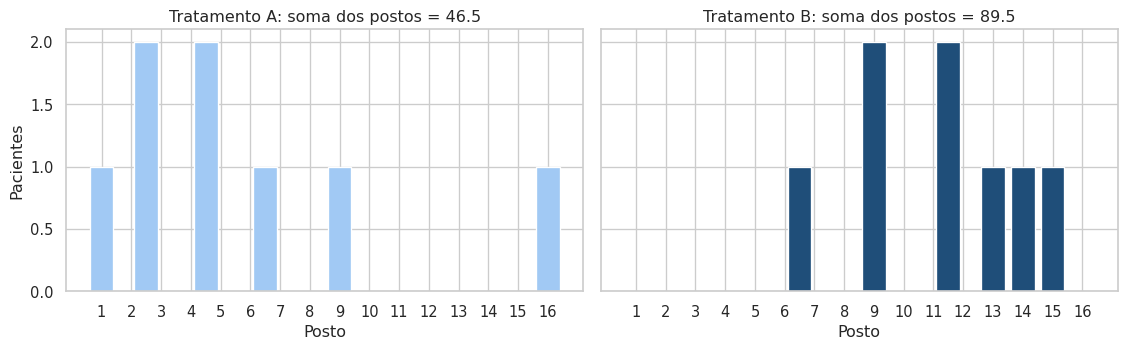

In [15]:
# Histograma dos postos de cada tratamento
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True, sharey=True)

for ax, (group, color) in zip(axes, [("A", "#A1C9F4"), ("B", "#1F4E79")]):
    ranks = ranked.loc[ranked["tratamento"] == group, "posto"]
    counts = ranks.value_counts()
    ax.bar(counts.index, counts.values, width=.8, color=color)
    ax.set(title=f"Tratamento {group}: soma dos postos = {ranks.sum():g}",
           xlabel="Posto", xticks=range(1, 17))

axes[0].set_ylabel("Pacientes")
plt.tight_layout()
plt.show()

Compare com os histogramas da seção 3.2. Na escala de dias, o paciente
de 120 dias esticava o eixo e escondia todo o resto. Na escala de
postos, os dois grupos ocupam o mesmo intervalo, de 1 a 16, e ele é
apenas a última barra de A. Fica fácil ver o que os dias escondiam: os
postos de A se concentram à esquerda, nos menores tempos, e os de B, à
direita.

Como a soma dos postos vira $U$? Imagine que o grupo A tivesse os 8
menores postos. A soma seria $1 + 2 + \dots + 8 = 36$, e A não ficaria
mais tempo em nenhum duelo, ou seja, $U_A = 0$. Esse é o **mínimo**
possível, e vale $n_A(n_A + 1)/2$. Agora, troque um paciente de A de
posição com o paciente de B imediatamente à sua direita. A soma dos
postos de A aumenta em 1 e, ao mesmo tempo, A passa a vencer exatamente
um duelo a mais. Cada ponto da soma acima do mínimo corresponde,
portanto, a um duelo em que A fica mais tempo, com meio ponto nos
empates. Por isso:

$$
U_A = W_A - \frac{n_A(n_A + 1)}{2}
$$

In [16]:
# Soma dos postos de cada grupo e U pela fórmula
w_a = ranked.loc[ranked["tratamento"] == "A", "posto"].sum()
w_b = ranked.loc[ranked["tratamento"] == "B", "posto"].sum()
N = len(ranked)
minimum = n_a * (n_a + 1) / 2

print(f"W_A = {w_a} · W_B = {w_b} · total = {w_a + w_b} = N(N + 1)/2")
print(f"U_A = {w_a} − {minimum} = {w_a - minimum}")
print(f"U_B = {w_b} − {minimum} = {w_b - minimum}")

W_A = 46.5 · W_B = 89.5 · total = 136.0 = N(N + 1)/2
U_A = 46.5 − 36.0 = 10.5
U_B = 89.5 − 36.0 = 53.5

Somar os postos e contar os duelos dão os mesmos valores:
$U_A = 46{,}5 - 36 = 10{,}5$ e $U_B = 89{,}5 - 36 = 53{,}5$. Na prática,
é a soma dos postos que os programas calculam, porque ela exige apenas
ordenar os dados uma vez.

## 3.9 O *p*-valor pela aproximação normal

Para saber quão raro é $U_A = 10{,}5$, usamos um atalho que já
conhecemos da Aula 8. Quando $H_0$ é verdadeira, os valores que $U_A$
pode assumir formam uma distribuição com **forma de sino**, muito
parecida com a curva normal. E, para usar uma curva normal, basta
conhecer duas coisas: o seu **centro** e a sua **largura**. Com elas, o
*p*-valor sai de uma área sob a curva, sem nenhuma simulação. O cálculo
tem quatro passos.

**1. Média esperada: onde fica o centro?** Sob $H_0$, nenhum tratamento
tende a tempos menores, e cada duelo tem a mesma chance de favorecer
qualquer lado, como uma moeda honesta. Dos 64 duelos, espera-se metade
para cada grupo:

$$
\mu_U = \frac{n_A n_B}{2} = \frac{64}{2} = 32
$$

**2. Dispersão: qual a largura da curva?** O centro não basta. Um $U_A$
a 21,5 pontos do centro pode ser comum ou raro, dependendo de quanto
$U_A$ costuma variar de uma amostra para outra quando $H_0$ é
verdadeira. Essa variação é medida pelo desvio-padrão $\sigma_U$. Repare
que a fórmula usa apenas os tamanhos dos grupos: como $U$ depende só dos
postos, e os postos são sempre os números de 1 a $N$, a variação
possível é a mesma para quaisquer dados com esses tamanhos. Sem empates:

$$
\sigma_U = \sqrt{\frac{n_A n_B (N + 1)}{12}} = \sqrt{\frac{64 \times 17}{12}} \approx 9{,}52
$$

**3. Correção para empates.** Quando há valores repetidos, eles recebem
o mesmo posto médio. Isso “achata” um pouco a ordenação: dois pacientes
empatados ocupam sempre o mesmo posto e não podem ser separados, e a
variação possível de $U_A$ diminui. A correção desconta essa redução.
Cada grupo de $t$ valores empatados contribui com $t^3 - t$, e valores
sem empate contribuem com zero:

$$
\sigma_U = \sqrt{\frac{n_A n_B}{12}\left[(N + 1) - \frac{\sum (t^3 - t)}{N(N - 1)}\right]}
$$

**4. Padronização e *p*-valor: quão longe estamos do centro?** Com o
centro e a largura, padronizamos $U_A$ exatamente como padronizamos as
alturas na seção 2.2: a distância até o centro, dividida pelo
desvio-padrão. O resultado é um $Z$ que, sob $H_0$, segue
aproximadamente a normal padrão. O *p*-valor é a área das duas caudas
além de $|Z|$:

$$
Z = \frac{U_A - \mu_U + 0{,}5}{\sigma_U}
\qquad\qquad
p = 2 \times P(Z \leq -|Z|)
$$

O $+0{,}5$ é a **correção de continuidade**. $U$ é uma contagem e só
assume valores em saltos de meio ponto, como 10, 10,5 e 11. A curva
normal, por outro lado, é contínua. Para que a curva represente bem a
contagem, deslocamos $U_A$ meio ponto **em direção ao centro**, o que
torna o teste um pouco mais conservador. Como aqui $U_A$ está abaixo de
$\mu_U$, somamos 0,5. Se estivesse acima, subtrairíamos.

O fator 2 no *p*-valor vem do teste bilateral: um $U_A$ tão afastado do
centro **para cima**, como o espelho 53,5, seria tão surpreendente
quanto o observado, e as duas caudas entram na conta.

In [17]:
# Os quatro passos da aproximação normal
mu_u = n_a * n_b / 2
sd_no_ties = np.sqrt(n_a * n_b * (N + 1) / 12)

ties = ranked["dias"].value_counts()
tie_sum = (ties ** 3 - ties).sum()
sd_u = np.sqrt(n_a * n_b / 12 * ((N + 1) - tie_sum / (N * (N - 1))))

z = (u_a - mu_u + 0.5 * np.sign(mu_u - u_a)) / sd_u
p = 2 * stats.norm.cdf(-abs(z))

print(f"1. μ_U = {mu_u}")
print(f"2. σ_U sem empates = {sd_no_ties:.2f}")
print(f"3. Σ(t³ − t) = {tie_sum} · σ_U com empates = {sd_u:.2f}")
print(f"4. Z = {z:.2f} · p = {p:.4f}")

1. μ_U = 32.0
2. σ_U sem empates = 9.52
3. Σ(t³ − t) = 48 · σ_U com empates = 9.47
4. Z = -2.22 · p = 0.0265

Vamos conferir cada passo com os números:

-   **Centro.** $\mu_U = 32$: sem efeito, A ficaria com metade dos 64
    duelos.
-   **Largura sem empates.** $\sigma_U \approx 9{,}52$.
-   **Empates.** Há quatro pares de valores repetidos (2, 3, 4 e 6 dias)
    e um trio (5 dias). Cada par contribui com $2^3 - 2 = 6$, e o trio,
    com $3^3 - 3 = 24$, o que dá
    $\sum (t^3 - t) = 4 \times 6 + 24 = 48$. A correção é pequena, de
    9,52 para 9,47, mas deixa $\sigma_U$ coerente com os dados.
-   **Padronização.**
    $Z = (10{,}5 - 32 + 0{,}5)/9{,}47 \approx -2{,}22$. O valor
    observado está a mais de dois desvios-padrão abaixo do centro.
-   ***p*-valor.** Como vimos na tabela da seção 2.2, um $|Z|$ de 2,22
    deixa cerca de 1,3% em cada cauda. Somando as duas,
    $p \approx 0{,}0265$.

A figura mostra a curva normal na escala de $U_A$, com o $Z$
correspondente no eixo de baixo. As áreas em laranja são as duas caudas
do *p*-valor, além do valor observado (10,5) e do seu espelho (53,5), à
mesma distância do centro:

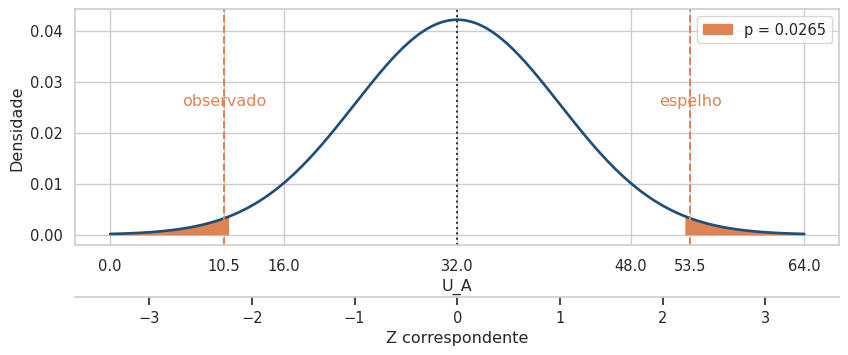

In [18]:
# Curva normal de U sob H0, com as duas caudas do p-valor
grid = np.linspace(0, n_a * n_b, 400)
density = stats.norm.pdf(grid, mu_u, sd_u)
mirror = n_a * n_b - u_a

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid, density, color="#1F4E79", linewidth=2)
tails = (grid <= u_a + 0.5) | (grid >= mirror - 0.5)
ax.fill_between(grid, density, where=tails, color="#DD8452", label=f"p = {p:.4f}")
for value, label in [(u_a, "observado"), (mirror, "espelho")]:
    ax.axvline(value, color="#DD8452", linestyle="--")
    ax.text(value, density.max() * 0.6, label, ha="center", color="#DD8452")
ax.axvline(mu_u, color="#333333", linestyle=":")
ax.set(xlabel="U_A", ylabel="Densidade", xticks=[0, 10.5, 16, 32, 48, 53.5, 64])
z_axis = ax.secondary_xaxis(-0.22, functions=(lambda u: (u - mu_u) / sd_u,
                                              lambda v: v * sd_u + mu_u))
z_axis.set_xlabel("Z correspondente")
ax.legend()
plt.tight_layout()
plt.show()

O SciPy faz todo o cálculo com `stats.mannwhitneyu`:

In [19]:
# Mann-Whitney pela aproximação normal no SciPy
mw_uti = stats.mannwhitneyu(group_a, group_b, method="asymptotic")

report("Mann-Whitney", mw_uti, stat="U")

Mann-Whitney: U = 10.500 · p = 0.027

O resultado coincide com o cálculo à mão. Em palavras: se o tratamento
não importasse, um $U_A$ tão ou mais distante de 32 teria probabilidade
de apenas 2,65%. Como $p < 0{,}05$, rejeitamos $H_0$.

> **Teste bilateral ou unilateral?**
>
> Até aqui, usamos o teste **bilateral**: a hipótese alternativa diz
> apenas que um dos tratamentos tende a tempos menores, qualquer que
> seja. Por isso, o *p*-valor soma as duas caudas da curva. Um $U_A$ tão
> afastado de 32 **para cima**, como o espelho 53,5, seria tão
> surpreendente quanto o observado.
>
> Às vezes, a pergunta tem uma direção definida desde o início. Se o
> hospital quisesse testar apenas se A **reduz** o tempo de internação,
> a alternativa seria unilateral: “A tende a tempos menores que B”.
> Nesse caso, só a cauda do lado previsto conta como evidência. O SciPy
> controla a direção com o argumento `alternative`:
>
> ``` python
> # O mesmo teste com as três hipóteses alternativas possíveis
> for alternative, h1 in [("two-sided", "A e B diferem"),
>                         ("less", "A tende a tempos menores"),
>                         ("greater", "A tende a tempos maiores")]:
>     result = stats.mannwhitneyu(group_a, group_b, alternative=alternative,
>                                 method="asymptotic")
>     print(f"{alternative:>9} · H1: {h1:<25} · p = {result.pvalue:.4f}")
> ```
>
>     two-sided · H1: A e B diferem             · p = 0.0265
>          less · H1: A tende a tempos menores  · p = 0.0133
>       greater · H1: A tende a tempos maiores  · p = 0.9899
>
> A figura mostra as áreas que formam cada *p*-valor:
>
> ``` python
> # Área do p-valor no teste bilateral e no unilateral à esquerda
> grid = np.linspace(-4, 4, 400)
> density = stats.norm.pdf(grid)
>
> fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
> for ax, tails, title in [
>     (axes[0], np.abs(grid) >= abs(z), "Bilateral: duas caudas"),
>     (axes[1], grid <= -abs(z), "Unilateral (less): só a cauda esquerda"),
> ]:
>     ax.plot(grid, density, color="#1F4E79", linewidth=2)
>     ax.fill_between(grid, density, where=tails, color="#DD8452")
>     ax.set(title=title, xlabel="Z")
> axes[0].set_ylabel("Densidade")
> plt.tight_layout()
> plt.show()
> ```
>
> 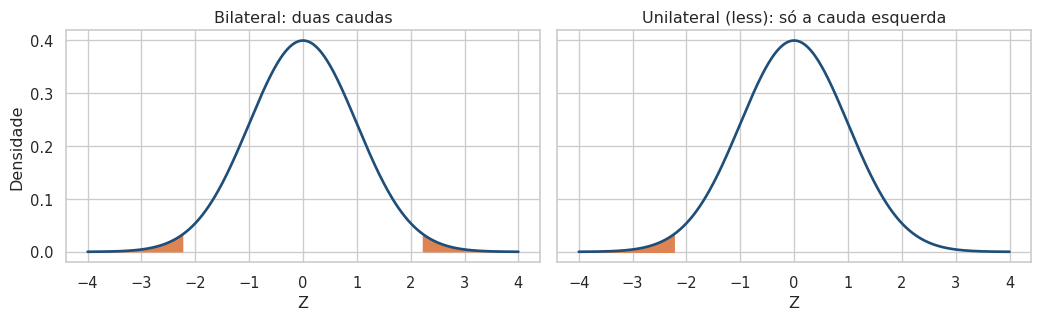
>
> Os três resultados têm uma relação simples:
>
> -   **Bilateral** ($p \approx 0{,}0265$): soma as duas caudas além de
>     $|Z| = 2{,}22$.
> -   **Unilateral `less`** ($p \approx 0{,}0133$): fica só com a cauda
>     esquerda, a do lado previsto. Por isso, vale cerca de **metade**
>     do bilateral.
> -   **Unilateral `greater`** ($p \approx 0{,}99$): aponta para o lado
>     oposto ao que os dados mostram. A evidência a favor dessa
>     alternativa é praticamente nula, e o *p* fica perto de 1.
>
> Se o unilateral dá um *p* menor, por que não usá-lo sempre? Porque a
> direção precisa ser escolhida **antes** de olhar os dados, com base na
> pergunta científica. Escolher o lado depois de ver qual grupo teve
> valores menores é desenhar o alvo depois dos tiros, como discutimos na
> Aula 7: o *p*-valor cai pela metade sem nenhuma evidência nova. Na
> dúvida, e sempre que um resultado na direção oposta também seria
> relevante, use o teste bilateral. No hospital, se B fosse o melhor
> tratamento, também gostaríamos de saber.

> **E o *p*-valor exato?**
>
> Com amostras pequenas, também seria possível obter o *p*-valor
> **exato** por permutação, como na Aula 7. Para este exemplo, ele vale
> cerca de 0,0238, muito próximo da aproximação normal. Não faremos esse
> cálculo nesta aula: com amostras maiores, ele exige recursos
> computacionais muito maiores, e a aproximação normal é o caminho
> usual.

## 3.10 Interpretação

O Mann-Whitney testa uma pergunta diferente da do Welch:

-   $H_0$: nenhum tratamento tende a ter tempos menores. As
    distribuições de A e B são iguais.
-   $H_1$: os tempos de um tratamento tendem a ser menores que os do
    outro.

Com $p \approx 0{,}027$, rejeitamos $H_0$: pacientes do tratamento A
tendem a ficar internados menos tempo que os de B. O Welch não rejeitou
a igualdade das médias ($p \approx 0{,}47$). Não há contradição, porque
os dois testes respondem a perguntas diferentes, e cada um dá um peso
diferente ao paciente de 120 dias:

| Leitura | Resultado | Como o paciente de 120 dias pesa |
|------------------------|------------------------|------------------------|
| Média · Welch | $p \approx 0{,}47$ | Pela magnitude: infla a média, o desvio-padrão e o erro-padrão |
| Ordem · Mann-Whitney | $p \approx 0{,}027$ | Só pela posição: é o posto 16 |
| Total de leitos | 140 contra 50 dias | Integralmente: é o custo real em dias de leito |

Nenhuma das leituras está errada. Para o paciente típico, A leva a altas
mais rápidas. Para o planejamento de leitos, A consumiu quase o triplo
de dias. A pergunta científica deve orientar a escolha do teste, e a
significância não deve orientar a escolha da pergunta.

> **Mann-Whitney não é, por si só, um teste de medianas**
>
> O Mann-Whitney avalia se os valores de um grupo **tendem** a ser
> menores que os do outro, o que se chama **dominância**. Ele só pode
> ser lido como diferença de medianas se as duas distribuições tiverem a
> mesma forma e diferirem apenas pela posição. Com formas diferentes, o
> teste pode rejeitar $H_0$ mesmo com medianas iguais.

# 4. Caso 1. Mann-Whitney em um teste A/B

Este caso corresponde ao **caso 2 da aula teórica** (slides 48 a 51).
Ele usa os mesmos dados e a mesma pergunta, agora resolvidos com o
cálculo passo a passo da seção 3.

> **Cenário**
>
> Um site testa dois layouts. Cada visitante vê o layout A ou o B, e
> medimos os segundos até o primeiro clique. Um visitante do layout A
> demorou 14 segundos, muito acima dos demais. Qual layout leva ao
> clique mais rápido?
>
> -   $H_0$: nenhum layout domina o outro: $P(A > B) = P(B > A)$.
> -   $H_1$: um layout tende a gerar tempos menores que o outro.

**Premissas do teste**

-   Observações independentes: cada visitante aparece em um único grupo.
-   Variável resposta pelo menos ordinal, para que os valores possam ser
    ordenados.
-   Para interpretar o resultado como diferença de localização, as duas
    distribuições devem ter formas semelhantes.

In [22]:
# Segundos até o primeiro clique em cada layout
layout_a = [2.1, 2.8, 3.0, 3.4, 3.7, 4.2, 4.6, 14.0]
layout_b = [3.9, 4.8, 5.0, 5.8, 6.1, 6.9, 7.7, 9.5]

O gráfico mostra cada visitante:

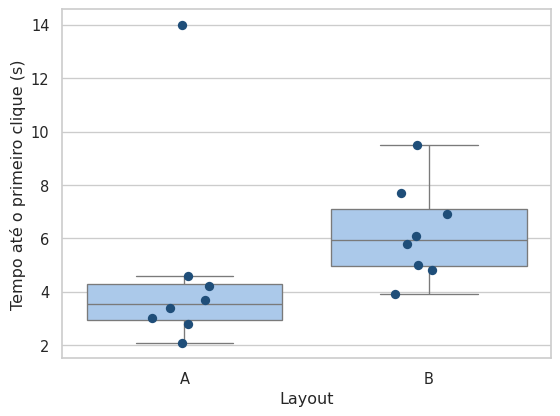

In [23]:
# Tempo até o primeiro clique por layout
clicks = pd.DataFrame(
    {"layout": ["A"] * 8 + ["B"] * 8, "segundos": layout_a + layout_b}
)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=clicks, x="layout", y="segundos", color="#A1C9F4",
            showfliers=False, ax=ax)
sns.stripplot(data=clicks, x="layout", y="segundos", color="#1F4E79",
              size=7, jitter=.15, ax=ax)
ax.set(xlabel="Layout", ylabel="Tempo até o primeiro clique (s)")
plt.tight_layout()
plt.show()

A caixa do layout A fica inteira abaixo da mediana do B, com um único
ponto isolado em 14 segundos. Talvez esse visitante tenha se distraído,
atendido o telefone ou demorado para encontrar o botão. Não sabemos, e
não temos motivo para descartá-lo. É a mesma situação do hospital: um
grupo concentrado em valores baixos e um único valor extremo. Por isso,
é um bom momento para verificar se você consegue repetir sozinho o
raciocínio da seção 3.

Como vamos repetir todos os passos da seção 3, eles ficam reunidos em
uma função. Aplicamos a função ao teste de layout e, para conferir, ao
exemplo do hospital:

In [24]:
# Postos, U, z e p-valor pela aproximação normal
def mann_whitney_steps(a, b):
    values = pd.Series(list(a) + list(b))
    ranks = values.rank(method="average")
    n_a, n_b, N = len(a), len(b), len(values)
    w_a = ranks[:n_a].sum()
    u_a = w_a - n_a * (n_a + 1) / 2
    ties = values.value_counts()
    tie_term = (ties ** 3 - ties).sum() / (N * (N - 1))
    sd_u = np.sqrt(n_a * n_b / 12 * ((N + 1) - tie_term))
    mu_u = n_a * n_b / 2
    z = (u_a - mu_u + 0.5 * np.sign(mu_u - u_a)) / sd_u
    delta = (2 * u_a - n_a * n_b) / (n_a * n_b)
    print(f"W_A = {w_a:g} · W_B = {ranks[n_a:].sum():g} · U_A = {u_a:g} · "
          f"Z = {z:.2f} · p = {2 * stats.norm.cdf(-abs(z)):.4f} · δ = {delta:.2f}")

mann_whitney_steps(layout_a, layout_b)
mann_whitney_steps(days_a, days_b)

W_A = 46 · W_B = 90 · U_A = 10 · Z = -2.26 · p = 0.0239 · δ = -0.69
W_A = 46.5 · W_B = 89.5 · U_A = 10.5 · Z = -2.22 · p = 0.0265 · δ = -0.67

Vamos ler a primeira linha passo a passo:

-   **Somas dos postos.** A soma dos postos de A é 46, e a de B, 90.
    Juntas, dão 136, como no hospital.
-   **Estatística U.** $U_A = 46 - 36 = 10$: em apenas 10 dos 64 duelos
    o visitante de A demorou mais. Nos outros 54, o visitante de A
    clicou antes.
-   **Aproximação normal.** $Z \approx -2{,}26$ e $p \approx 0{,}024$.
    Não há tempos repetidos no layout, e a correção para empates vale
    zero.

A segunda linha reproduz os números da seção 3, o que confirma que a
função faz os mesmos passos que fizemos à mão.

A função também calcula o **δ de Cliff**, o tamanho de efeito do
Mann-Whitney. Assim como o *d* de Cohen mede o tamanho de uma diferença
de médias, o δ mede o tamanho da dominância. Ele é a diferença entre
duas proporções de duelos:

$$
\delta = P(A > B) - P(A < B) = \frac{U_A - U_B}{n_A n_B}
$$

No layout, A vence 10 dos 64 duelos (16%) e perde 54 (84%). O δ é
$0{,}16 - 0{,}84 \approx -0{,}69$. O valor varia de −1, quando todos os
valores de A são menores, a +1, quando todos são maiores, e vale 0
quando nenhum grupo domina. Valores de $|\delta|$ acima de cerca de 0,47
costumam ser descritos como efeitos grandes. Aqui, o sinal negativo
indica que A tende a ter tempos **menores**, e o tamanho indica um
efeito grande.

Comparamos com o teste de Welch:

In [25]:
# Mann-Whitney e Welch no teste de layout
mw_layout = stats.mannwhitneyu(layout_a, layout_b, method="asymptotic")

welch_layout = stats.ttest_ind(layout_a, layout_b, equal_var=False)

report("Mann-Whitney", mw_layout, stat="U")
report("t de Welch", welch_layout, stat="t")

Mann-Whitney: U = 10.000 · p = 0.024
t de Welch: t = -0.995 · gl = 9.926 · p = 0.343

**Interpretação.** Se os dois layouts fossem equivalentes, uma ordenação
tão desequilibrada seria rara ($p \approx 0{,}024$). Rejeitamos $H_0$:
visitantes do layout A tendem a clicar antes, com efeito grande.

O teste de Welch conta outra história ($p \approx 0{,}34$). O visitante
de 14 segundos infla a média do layout A para 4,7 segundos, perto da
média de B, e aumenta muito o desvio-padrão de A. Com o sinal menor e o
ruído maior, a diferença desaparece na comparação de médias. Para a
equipe de produto, a mensagem do Mann-Whitney é a mais útil: o visitante
típico do layout A encontra o que procura mais rápido.

> **Note**
>
> Os slides apresentam $p = 0{,}021$ para este caso. É o *p*-valor
> **exato**, obtido por permutação, um cálculo que não fazemos nesta
> aula. A aproximação normal dá um valor muito próximo, 0,024, e leva à
> mesma decisão.

# 5. Caso 2. Pearson e Spearman

Este caso corresponde ao **caso 5 da aula teórica** (slides 60 a 63).
Aqui ele se concentra na comparação entre os coeficientes de Pearson e
de Spearman. O coeficiente de Kendall, também apresentado nos slides,
fica de fora deste roteiro.

> **Cenário**
>
> No `mtcars`, carros mais potentes (`hp`) fazem menos milhas por galão
> (`mpg`). Mas a relação entre potência e consumo é uma reta ou só uma
> tendência que sempre desce? A escolha do coeficiente de correlação
> depende dessa resposta.
>
> -   $H_0$: não há associação monotônica entre potência e consumo
>     ($\rho = 0$).
> -   $H_1$: há associação monotônica ($\rho \neq 0$).

**Premissas do teste**

-   Pares de observações independentes entre si.
-   Variáveis pelo menos ordinais, para que possam ser ordenadas.
-   Relação **monotônica**: quando uma variável cresce, a outra sempre
    cresce ou sempre decresce, em linha reta ou não.

In [26]:
# Carrega a base de carros
mtcars = pd.read_csv("mtcars/data/mtcars.csv")

## 5.1 Os dois coeficientes

O coeficiente de **Pearson**, visto na Aula 8, mede o quanto os pontos
seguem uma **reta**. Ele usa os valores originais e, por isso, é
sensível à forma da relação e a valores extremos.

O coeficiente de **Spearman** aplica a ideia dos postos à correlação.
Cada variável é ordenada separadamente: o carro menos potente recebe o
posto 1 em `hp`, e o menos econômico recebe o posto 1 em `mpg`. Depois,
calculamos a correlação de Pearson entre essas posições. A pergunta
deixa de ser “os pontos seguem uma reta?” e passa a ser “quando um carro
sobe no ranking de potência, ele desce no ranking de consumo?”.

Calculamos os dois coeficientes e, para mostrar que Spearman é de fato
um Pearson sobre os postos, calculamos também o Pearson dos postos à
mão:

In [27]:
# Pearson nos valores, Spearman e Pearson calculado sobre os postos
ranks_hp = mtcars["hp"].rank()
ranks_mpg = mtcars["mpg"].rank()

pearson_values = stats.pearsonr(mtcars["hp"], mtcars["mpg"])
spearman = stats.spearmanr(mtcars["hp"], mtcars["mpg"])
pearson_ranks = stats.pearsonr(ranks_hp, ranks_mpg)

report("Pearson (valores)", pearson_values, stat="r")
report("Spearman", spearman, stat="ρ")
report("Pearson (postos)", pearson_ranks, stat="r")

Pearson (valores): r = -0.776 · p < 0.001
Spearman: ρ = -0.895 · p < 0.001
Pearson (postos): r = -0.895 · p < 0.001

O Pearson dos valores dá $r \approx -0{,}78$, uma correlação negativa
forte. O Spearman dá $\rho \approx -0{,}89$, ainda mais forte, e é
exatamente o mesmo número que o Pearson calculado sobre os postos. Não
há mágica no Spearman: ele é a correlação de sempre, aplicada às
posições.

Existe também uma fórmula clássica, construída a partir das diferenças
$d_i$ entre os dois postos de cada carro. Veja três exemplos:

| Carro         | Posto em `hp`     | Posto em `mpg`                  | $d$   |
|---------------|-------------------|---------------------------------|-------|
| Honda Civic   | 1 (menos potente) | 29,5 (entre os mais econômicos) | −28,5 |
| Merc 280      | 16,5              | 16,5                            | 0     |
| Maserati Bora | 32 (mais potente) | 6 (entre os menos econômicos)   | +26   |

Se a associação fosse perfeitamente negativa, o carro com o posto 1 em
potência teria o posto 32 em consumo, e assim por diante, e as
diferenças seriam máximas. Se não houvesse associação, as diferenças
seriam aleatórias. A fórmula resume tudo isso em um número entre −1 e
+1:

$$
\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}
$$

In [28]:
# Fórmula clássica de Spearman com as diferenças de postos
d = ranks_hp - ranks_mpg
n = len(mtcars)

print(f"Σd² = {(d ** 2).sum()}")
print(f"ρ pela fórmula = {1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1)):.3f}")

Σd² = 10315.5
ρ pela fórmula = -0.891

A fórmula dá −0,891, muito perto do valor do SciPy (−0,895). A pequena
diferença vem dos empates: há carros com a mesma potência e outros com o
mesmo consumo, e a fórmula clássica só é exata quando não há valores
repetidos. Ela é útil para entender a lógica do coeficiente, mas, na
prática, usamos `stats.spearmanr`, que trata os empates corretamente.

## 5.2 Valores e postos lado a lado

O gráfico mostra por que os coeficientes diferem. À esquerda, os valores
originais. À direita, os postos das mesmas variáveis. Em cada painel, a
reta laranja é a que melhor descreve os pontos:

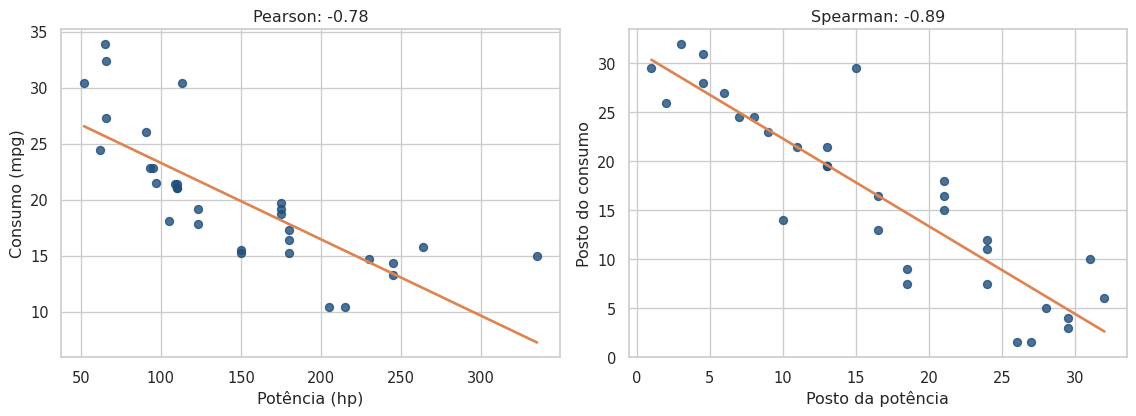

In [29]:
# Dispersão dos valores e dos postos, com a reta de mínimos quadrados
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

panels = [
    (mtcars["hp"], mtcars["mpg"], "Potência (hp)", "Consumo (mpg)", "Pearson"),
    (ranks_hp, ranks_mpg, "Posto da potência", "Posto do consumo", "Spearman"),
]

for ax, (x, y, xlabel, ylabel, name) in zip(axes, panels):
    slope, intercept = np.polyfit(x, y, deg=1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, y, color="#1F4E79", alpha=.8)
    ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
    ax.set(xlabel=xlabel, ylabel=ylabel,
           title=f"{name}: {stats.pearsonr(x, y).statistic:.2f}")

plt.tight_layout()
plt.show()

Compare os dois painéis com calma:

-   **Valores originais, à esquerda.** Os pontos descem em curva: o
    consumo cai rápido entre os carros de baixa potência, até cerca de
    150 hp, e depois se estabiliza. A reta não consegue acompanhar essa
    curva. Ela fica abaixo dos pontos nos dois extremos e acima deles no
    meio, e o Pearson perde força por isso.
-   **Postos, à direita.** A curva é “esticada”. Como os postos guardam
    só a ordem, as distâncias entre os carros de baixa potência e entre
    os de alta potência passam a valer o mesmo. Os pontos se alinham
    muito melhor ao longo da reta.

A relação entre potência e consumo é a mesma nos dois painéis. O que
muda é o que cada coeficiente pergunta. O Pearson pergunta se a relação
é uma reta, e a resposta é “mais ou menos”. O Spearman pergunta se a
ordem se mantém, e a resposta é “quase sempre”: mais potência quase
sempre significa menos milhas por galão.

**Interpretação.** Se potência e consumo não tivessem associação, um
$\rho$ tão forte seria praticamente impossível por acaso
($p < 0{,}001$). Rejeitamos $H_0$: a associação é negativa, forte e
monotônica. O Pearson subestima essa força porque mede só a parte linear
de uma relação curva. Na Aula 8, vimos que transformar a potência em log
aproxima o Pearson do Spearman, pelo mesmo motivo.

## 5.3 Quando usar cada um

|  | Pearson ($r$) | Spearman ($\rho$) |
|------------------------|------------------------|------------------------|
| Usa | Os valores | Os postos |
| Mede | Associação **linear** | Associação **monotônica** |
| Valores atípicos | Muito sensível | Influência limitada |
| Escala | Intervalar ou razão | Também ordinal |
| Transformação crescente (log, raiz) | Muda o coeficiente | Não muda: a ordem é a mesma |
| Quando preferir | Relação reta, dados sem extremos | Relação curva, extremos ou escala ordinal |

Uma regra prática: calcule os dois coeficientes e compare. Se forem
parecidos, a relação é aproximadamente linear, e o Pearson descreve bem
os dados. Se o Spearman for bem mais forte, a relação provavelmente é
curva ou há valores extremos influenciando o Pearson. Em qualquer caso,
o gráfico de dispersão é obrigatório: nenhum coeficiente substitui olhar
os dados.

# 6. Guia rápido

A tabela reúne os testes não paramétricos mais usados e o teste
paramétrico que cada um substitui. Os testes marcados com ✓ foram
trabalhados neste roteiro. Os demais foram apresentados na aula teórica
e seguem a mesma lógica: trocam os valores pelos postos.

| Desenho | Paramétrico (Aula 8) | Não paramétrico | Python (`scipy.stats`) | Tamanho de efeito | Neste roteiro |
|------------|------------|------------|------------|------------|------------|
| 1 amostra contra uma meta | *t* de uma amostra | Wilcoxon de 1 amostra | `wilcoxon(x - meta)` | $r = z / \sqrt{n}$ |  |
| 2 grupos independentes | *t* de Welch | Mann-Whitney U | `mannwhitneyu(x, y)` | δ de Cliff | ✓ seção 3 e caso 1 |
| 2 grupos pareados (antes e depois) | *t* pareado | Wilcoxon pareado | `wilcoxon(x, y)` | $r = z / \sqrt{n}$ |  |
| 3 ou mais grupos independentes | ANOVA one-way | Kruskal-Wallis + Dunn | `kruskal(g1, g2, g3)` | $\eta^2_H$ |  |
| Associação entre duas variáveis | Pearson ($r$) | Spearman ($\rho$) · Kendall ($\tau$) | `spearmanr(x, y)` · `kendalltau(x, y)` | O próprio $\rho$ ou $\tau$ | ✓ caso 2 (Spearman) |

Duas observações ajudam a usar a tabela:

-   **Wilcoxon de 1 amostra e pareado.** São o mesmo teste. No pareado,
    ele é aplicado às diferenças $D_i = X_{2i} - X_{1i}$ de cada par. Os
    postos são calculados sobre o tamanho das diferenças, $|D_i|$, e
    depois recebem o sinal da diferença.
-   **Kruskal-Wallis.** Generaliza o Mann-Whitney para três ou mais
    grupos, como a ANOVA generaliza o teste *t*. Quando ele rejeita
    $H_0$, o teste de Dunn, disponível no pacote `scikit_posthocs`,
    indica quais pares de grupos diferem, com correção para múltiplas
    comparações.

| Conceito | Resumo |
|------------------------------------|------------------------------------|
| Posto | Posição na ordenação conjunta. Empates recebem o posto médio |
| $W$ | Soma dos postos de um grupo. As somas dos dois grupos totalizam $N(N+1)/2$ |
| $U$ | $W - n(n+1)/2$: número de pares em que o grupo tem o maior valor, com meio ponto por empate |
| Aproximação normal | $Z = (U_A - n_A n_B / 2 \pm 0{,}5) / \sigma_U$, com correção para empates. O $\pm 0{,}5$ aproxima $U_A$ do centro |
| δ de Cliff | $(U_A - U_B)/(n_A n_B)$: tamanho de efeito entre −1 e +1 |
| Distribuição Z | Normal padronizada, com média 0 e desvio-padrão 1. O *p* bilateral é `2 * stats.norm.cdf(-abs(z))` |

## Síntese

1.  **Postos preservam a ordem e limitam a magnitude.** O paciente de
    120 dias continua na análise, mas vale apenas uma posição.
2.  **Mann-Whitney mede dominância.** $U$ conta, entre todos os pares de
    grupos diferentes, quantas vezes um grupo supera o outro.
3.  **A aproximação normal dá o *p*-valor.** $U$ é padronizado pelo seu
    valor esperado e pelo seu desvio-padrão sob $H_0$, como as
    estatísticas da Aula 8.
4.  **Cada teste responde à sua pergunta.** O Welch pergunta pelas
    médias, e o Mann-Whitney, pela ordenação. Resultados diferentes não
    são contraditórios.
5.  **Spearman é Pearson sobre os postos.** Ele capta relações
    monotônicas, curvas ou não, e é menos sensível a valores extremos.
6.  **Livre de distribuição não é livre de premissas.** A independência
    das observações continua obrigatória.

# Perguntas para consolidar

**Pergunta 1: Mann-Whitney significante quer dizer medianas
diferentes?**

No exemplo do hospital, o Mann-Whitney rejeitou $H_0$. Isso prova que a
mediana de A é menor que a de B?

> **Como pensar sobre isso**
>
> Não necessariamente. O Mann-Whitney mostra que os tempos de A
> **tendem** a ser menores nas comparações entre pacientes dos dois
> grupos. Essa tendência só equivale a uma diferença de medianas quando
> as duas distribuições têm a mesma forma e diferem apenas pela posição.
> No hospital, as formas são bem diferentes: A tem sete pacientes
> concentrados e um extremo, e B é um bloco compacto. Com formas
> diferentes, é possível ter dominância mesmo com medianas iguais.

**Pergunta 2: e se o paciente tivesse ficado 3.650 dias?**

Se o paciente de 120 dias tivesse ficado 3.650 dias internado, o que
aconteceria com o seu posto, com $W_A$, com $U$ e com o *p*-valor do
Mann-Whitney? E com o *p*-valor do Welch?

> **Como pensar sobre isso**
>
> O posto continuaria sendo 16, porque ele já era o maior valor. Por
> isso, $W_A = 46{,}5$, $U_A = 10{,}5$ e o *p*-valor do Mann-Whitney não
> mudariam. Já o Welch mudaria bastante: a média e o desvio-padrão de A
> ficariam ainda maiores, e o erro-padrão cresceria junto. A importância
> clínica de uma internação de dez anos, porém, não desaparece. Os
> postos limitam a influência da magnitude no teste, e não no
> significado do resultado.

**Pergunta 3: o paciente de 120 dias mudou a conclusão?**

Pela média, não rejeitamos a igualdade. Pela ordenação, A tende a tempos
menores. Pelos leitos, A consumiu 140 dias contra 50 de B. Qual dessas
leituras está certa?

> **Como pensar sobre isso**
>
> Todas estão certas, porque respondem a perguntas diferentes. Se a
> pergunta é sobre o paciente típico, a ordenação mostra que A leva a
> altas mais rápidas. Se a pergunta é sobre a ocupação total de leitos,
> o total de dias mostra que A foi mais custoso. Um único paciente pode
> mudar a conclusão quando a pergunta é sobre médias. A exceção não é um
> erro a descartar: ela entra de formas diferentes em cada medida.

**Pergunta 4: o sinal de Z importa?**

No exemplo do hospital, obtivemos $Z \approx -2{,}22$. Se um colega
tivesse comparado B contra A, em vez de A contra B, obteria
$Z \approx +2{,}22$. O *p*-valor muda?

> **Como pensar sobre isso**
>
> Não. Trocar a ordem dos grupos troca $U_A$ por $U_B$ e, com isso,
> apenas o sinal de $Z$: o valor observado passa a ficar à mesma
> distância do centro, do outro lado. Como a curva normal é simétrica e
> o teste é bilateral, o *p*-valor soma as duas caudas além de $|Z|$ e é
> o mesmo nos dois casos, cerca de 0,027. O sinal só informa **qual**
> grupo tende a valores menores. Em um teste unilateral, que olha para
> um único lado, o sinal passaria a importar para a decisão.

# Para casa

1.  No exemplo do hospital, meça o tempo em horas e, depois, aplique o
    log aos dias. Em cada caso, o *p*-valor do Welch muda? E o do
    Mann-Whitney? Explique o resultado pela ordem dos valores.
2.  Use `mann_whitney_steps` para comparar a massa corporal de pinguins
    machos e fêmeas da espécie Adelie (Aula 8). Compare o *p*-valor com
    o do teste de Welch e o δ de Cliff com a diferença de médias.
3.  No `mtcars`, compare Pearson e Spearman entre o peso (`wt`) e o
    consumo (`mpg`). Os coeficientes divergem tanto quanto no caso 2? O
    que isso indica sobre a forma da relação?
4.  Antes de considerar o notebook pronto, use Restart Kernel and Run
    All.

## Referências

1.  Mann, H. B.; Whitney, D. R. On a test of whether one of two random
    variables is stochastically larger than the other. *Annals of
    Mathematical Statistics*, 18(1), 50-60, 1947.
2.  Spearman, C. The proof and measurement of association between two
    things. *American Journal of Psychology*, 15(1), 72-101, 1904.
3.  Cliff, N. Dominance statistics: ordinal analyses to answer ordinal
    questions. *Psychological Bulletin*, 114(3), 494-509, 1993.
4.  Bruce, P.; Bruce, A.; Gedeck, P. *Practical Statistics for Data
    Scientists*. 2. ed. O’Reilly, 2020.